# Best GH

- Input parameters
  - Number of groups
  - Name ref variable
  - Name perf variable
 

- Options
  - Tree/graph search problem approach
     - Data structures:
         - Set of visited states
         - Priority queue sorted by minimum fitness function value
         - Attribute to keep the current best visited state
     
     - Initialization:
         - Based on the provided number of groups, obtain n-tiles per ref
         - Obtain mean perf value for each tile for each ref
         - Caclculate the mean perf std deviation of each tile across the refs
         - Fitness function: sum of tiles std. devs

     - Iteration:
         - Select the tile with the largest mean perf variance
         - Generate 2 new states:
           - Observation with highest positive std deviation within the tile*  is assigned to upper tile
           - Observation with lowest (highest negative) std deviation within the tile* is assigned to lower tile
         - Calculate fitness function for each new state
         - Check if new states yield better (lower) fitness function value than current 
         - Add both new states to a priroty queue based on their fitness function value
         - Add current state to visited states set
         - Advance to the (already prioritized) next state on queue

    *obtained by averaging the std dev of each obs across the tiles



  - Linear optimization problem approach
    - Minimize sum of tile's std_dev(X:bad) subject to a reasonable ordination(Y:score) across refs and tiles

# Auto GH

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( x[x[perf] > 0].shape[0] / x[~(x[perf] > 0)].shape[0]
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

In [2]:
def check_gh(
    df,
    ref,
    perf,
    gh,
    gh_min_size=0.05,
    z_min=2,
    perf_denominator=None
):
    # Calculate percentage of GH by ref 
    df_count = df.groupby(by=[ref, gh])[[ref, gh]].apply( lambda x: pd.Series({"percentage": len(x)}))
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)["percentage"].transform('sum')
    # print(df_count)
    df_count.reset_index(inplace=True)
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
    else: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
        df_perf[perf] = (df_perf[perf]/df.groupby([ref, gh])[perf_denominator].sum().values)

    # Generate the check report by GH and calculating 
    report = df_count.groupby(gh, as_index=False)[
        "percentage"
    ].mean() # Mean percentage by GH
    
    # Mean perf by GH
    report["mean_perf"] = df_perf.groupby(gh)[perf].mean().values
    #Std dev of perf by GH
    report["std_perf"] = df_perf.groupby(gh)[perf].std().values
    # Mean perf of previous GH
    report["mean_prev"] = report["mean_perf"].shift(1)
    # Std dev of perf of previous GH
    report["std_prev"] = report["std_perf"].shift(1)
    
    # Calculate z-score
    report["z"] = (report["mean_perf"] - report["mean_prev"]) / ((report["std_perf"] ** 2 + report["std_prev"] ** 2) ** 0.5)
    #Check column
    report["ok"] = (report["percentage"] > gh_min_size) & ((report["mean_prev"].isna()) | (report["z"] > z_min))
    # Set GH as index
    report = report.set_index(gh)
    return report

In [3]:
def get_cut_points(
    df,
    ref,
    perf,
    score,
    gh_min_size=0.05,
    z_min=2,
    step=0.01,
    perf_denominator=None
):
    # Initial cut points 
    cut_points = [0, 1]
    # Flag that indicates to continue 
    not_end = True
    # Instantiate progress bar 
    pbar = tqdm(total=len(np.arange(step, 1, step)), position=0, leave=True)
    
    while not_end:
        # Set flag to stop if no one new point be found 
        not_end = False
        # Loop thru every step 
        for i in np.arange(cut_points[-2] + step, 1, step):
            # Update progress bar
            pbar.update(1)
            # Insert new point in the end 
            new_cut_points = cut_points[:-1] + [i] + cut_points[-1:]
            # Create GH Labels 
            labels = np.arange(1, len(new_cut_points))
            # Create dataframe with GHS
            gh = pd.DataFrame(
                {"gh": pd.cut(df[score], bins=new_cut_points, labels=labels)}
            )
            
            # Check if all GHS are 'ok' with constraints
            if check_gh(
                pd.concat([df, gh], axis=1),
                ref,
                perf,
                "gh",
                gh_min_size,
                z_min,
                perf_denominator,
            )["ok"].all():
                # Update cut points
                cut_points = new_cut_points
                # Set flat to continue looking for new cut points
                not_end = True
                break

    pbar.close()
    return [float(cp) for cp in cut_points] 

In [4]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs

In [5]:
import numpy as np
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

ref = [2306]*40 + [2307]*40 + [2308]*38
perf = [0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*8
score = list(np.linspace(0,1,118))

In [6]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

[2307, 2308, 2306, 2307, 2306, 2308, 2307, 2306, 2308, 2307]

In [7]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [8]:
df.SAFRA.value_counts()

SAFRA
2307    40
2306    40
2308    38
Name: count, dtype: int64

In [9]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.461111
2307    0.491239
2308    0.550157
Name: SCORE, dtype: float64

In [10]:
df.groupby('SAFRA').PERF.mean()

SAFRA
2306    0.150000
2307    0.150000
2308    0.157895
Name: PERF, dtype: float64

In [11]:
df.head()

,SAFRA,PERF,SCORE
0,2307,0,0.000000
1,2308,0,0.008547
2,2306,0,0.017094
3,2307,0,0.025641
4,2306,0,0.034188


In [12]:
df['SAFRA']

0      2307
1      2308
2      2306
3      2307
4      2306
       ... 
113    2308
114    2306
115    2308
116    2307
117    2308
Name: SAFRA, Length: 118, dtype: int64

In [13]:
cp = get_cut_points(df,'SAFRA','PERF','SCORE',z_min=0.5, step=0.01)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 99/99 [00:01<00:00, 64.29it/s]


In [14]:
cp

[0.0, 0.060000000000000005, 0.4299999999999998, 0.5299999999999999, 0.65, 1.0]

In [15]:
df['GH'] = get_gh(df,'SCORE',cp)
df.GH.fillna(1,inplace=True)

In [16]:
df.GH.value_counts()

GH
2    43
5    41
4    14
3    12
1     8
Name: count, dtype: int64

In [17]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


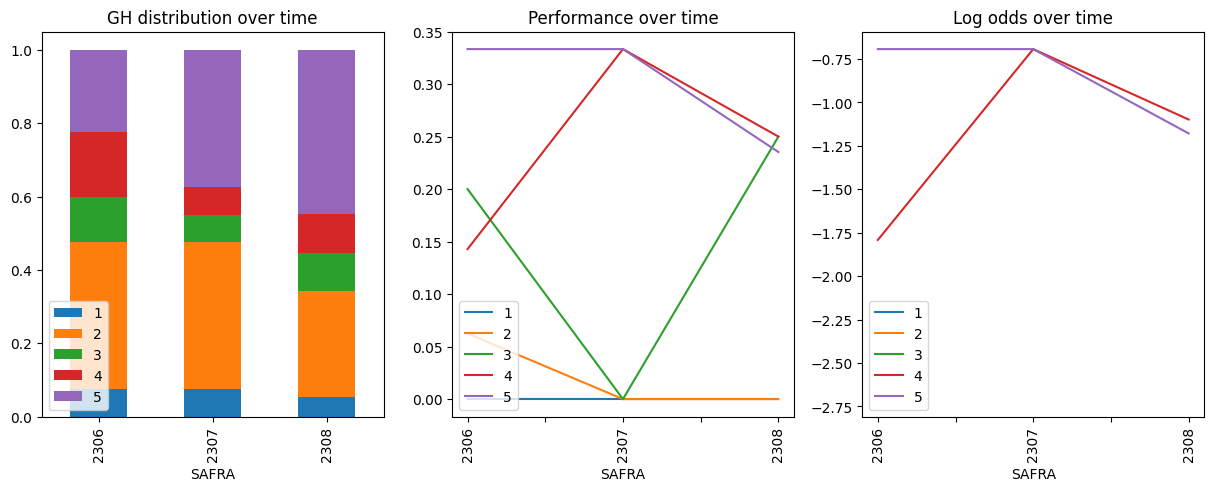

In [18]:
plot_gh(df, 'SAFRA', 'PERF', 'GH')

In [19]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


In [20]:
df.groupby(['GH','SAFRA']).PERF.mean().unstack().sort_index(ascending=False)

SAFRA,2306,2307,2308
GH,,,
5,0.333333,0.333333,0.235294
4,0.142857,0.333333,0.250000
3,0.200000,0.000000,0.250000
2,0.062500,0.000000,0.000000
1,0.000000,0.000000,0.000000


In [21]:
df.loc[df.SAFRA==2308]

,SAFRA,PERF,SCORE,GH
1,2308,0,0.008547,1
5,2308,0,0.042735,1
8,2308,0,0.068376,2
11,2308,0,0.094017,2
13,2308,0,0.111111,2
16,2308,0,0.136752,2
18,2308,0,0.153846,2
19,2308,0,0.162393,2
22,2308,0,0.188034,2
28,2308,0,0.239316,2


In [22]:
pd.DataFrame(np.hstack([df[df.SAFRA==ref].sort_values('SCORE') for ref in np.sort(df['SAFRA'].unique())]), columns=['SAFRA_1','PERF_1','SCORE_1','GH_1', 'SAFRA_2','PERF_2','SCORE_2','GH_2', 'SAFRA_3','PERF_3','SCORE_3','GH_3'])

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 40 and the array at index 2 has size 38

# Best GH

In [22]:
from pulp import *

In [23]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [24]:
refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
refs_list

[2306, 2307, 2308]

In [25]:
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
groups_list

[1, 2, 3, 4]

In [28]:
#idx_list = [str(i) for i in range(0,np.max([len(df[df[safra]==int(ref)]) for ref in refs_list]))]
idx_list = [[i+1 for i in range(0,len(df[df[safra]==ref]))] for ref in refs_list]
idx_list

[[1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]]

In [29]:
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}
idx_dict

{2306: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2307: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2308: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]}

In [ ]:
VI1G1R1 ==> assigning vars

BADG1R1 => (VI1G1R1*PERF[I1,R1] + VI2G1R1*PERF[I2,R1] + VI3G1R1*PERF[I3,R1] ...) / (VI1G1R1 + VI2G1R1 + VI3G1R1 + ...)
BADG2R1 => (VI1G2R1*PERF[I1,R1] + VI2G2R1*PERF[I2,R1] + VI3G2R1*PERF[I3,R1] ...) / (VI1G2R1 + VI2G2R1 + VI3G2R1 + ...)
BADG3R1 => (VI1G3R1*PERF[I1,R1] + VI2G3R1*PERF[I2,R1] + VI3G3R1*PERF[I3,R1] ...) / (VI1G3R1 + VI2G3R1 + VI3G3R1 + ...)
BADG4R1 => (VI1G4R1*PERF[I1,R1] + VI2G4R1*PERF[I2,R1] + VI3G4R1*PERF[I3,R1] ...) / (VI1G4R1 + VI2G4R1 + VI3G4R1 + ...)

BADG1R2 => (VI1G1R2*PERF[I1,R2] + VI2G1R2*PERF[I2,R2] + VI3G1R2*PERF[I3,R2] ...) / (VI1G1R2 + VI2G1R2 + VI3G1R2 + ...)
BADG2R2 => (VI1G2R2*PERF[I1,R2] + VI2G2R2*PERF[I2,R2] + VI3G2R2*PERF[I3,R2] ...) / (VI1G2R2 + VI2G2R2 + VI3G2R2 + ...)
BADG3R2 => (VI1G3R2*PERF[I1,R2] + VI2G3R2*PERF[I2,R2] + VI3G3R2*PERF[I3,R2] ...) / (VI1G3R2 + VI2G3R2 + VI3G3R2 + ...)
BADG4R2 => (VI1G4R2*PERF[I1,R2] + VI2G4R2*PERF[I2,R2] + VI3G4R2*PERF[I3,R2] ...) / (VI1G4R2 + VI2G4R2 + VI3G4R2 + ...)

BADG1R3 => (VI1G1R3*PERF[I1,R3] + VI2G1R3*PERF[I2,R3] + VI3G1R3*PERF[I3,R3] ...) / (VI1G1R3 + VI2G1R3 + VI3G1R3 + ...)
BADG2R3 => (VI1G2R3*PERF[I1,R3] + VI2G2R3*PERF[I2,R3] + VI3G2R3*PERF[I3,R3] ...) / (VI1G2R3 + VI2G2R3 + VI3G2R3 + ...)
BADG3R3 => (VI1G3R3*PERF[I1,R3] + VI2G3R3*PERF[I2,R3] + VI3G3R3*PERF[I3,R3] ...) / (VI1G3R3 + VI2G3R3 + VI3G3R3 + ...)
BADG4R3 => (VI1G4R3*PERF[I1,R3] + VI2G4R3*PERF[I2,R3] + VI3G4R3*PERF[I3,R3] ...) / (VI1G4R3 + VI2G4R3 + VI3G4R3 + ...)

BADG1R1 = Z11 ==> CONSTRAINT ==> Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx) / SUM(assignment_vars[(1,1,idx)])
                                 SUM(assignment_vars[(1,1,idx)]) * Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)

                           U11 = SUM(assignment_vars[(1,1,idx)]) * Z11 ==> U11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)
                                                                           U11 >= 0*Z11
                                                                           U11 <= SUM(PERF[(1,idx)] for idx)*Z11

-----------------------------------------------------------------------------------------------------------------------

MEDG1 => (BADG1R1 + BADG1R2 + BADG1R3) * INVERSO_TOTAL_REFS
MEDG2 => (BADG2R1 + BADG2R2 + BADG2R3) * INVERSO_TOTAL_REFS
MEDG3 => (BADG3R1 + BADG3R2 + BADG3R3) * INVERSO_TOTAL_REFS
MEDG4 => (BADG4R1 + BADG4R2 + BADG4R3) * INVERSO_TOTAL_REFS

MEDG1 = Y1 ==> CONSTRAINT ==> TOTAL_REFS * Y1 = SOMA(Z11,Z12,Z13) 
-----------------------------------------------------------------------------------------------------------------------

STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
STDDEVG2 => SOMA([|BADG2R1-MEDG2|,|BADG2R2-MEDG2|,|BADG2R3-MEDG2|]) * INVERSO_TOTAL_REFS
STDDEVG3 => SOMA([|BADG3R1-MEDG3|,|BADG3R2-MEDG3|,|BADG3R3-MEDG3|]) * INVERSO_TOTAL_REFS
STDDEVG4 => SOMA([|BADG4R1-MEDG4|,|BADG4R2-MEDG4|,|BADG4R3-MEDG4|]) * INVERSO_TOTAL_REFS

STDDEVG1 = X1 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (|Z11-Y1| + |Z12-Y1| + |Z13-Y1|)
|Z11-Y1| = W11 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (W11 + W12 + W13) 
                                   Z11-Y1 <= W11
                                   Y1-Z11 <= W11
-----------------------------------------------------------------------------------------------------------------------

MIN(STDDEVG1+STDDEVG2+STDDEVG3+STDDEVG4)

MIN(X1+X2+X3+X4)

In [155]:
def generate_best_gh_problem(df, ref_var, perf_var, n_groups):
    refs_list = sorted([sfr for sfr in df[ref_var].unique()])
    groups_list = sorted([grp for grp in np.arange(1,n_groups+1)])
    idx_dict = {ref:[i for i in range(1,len(df[df[ref_var]==ref]) + 1)] for ref in refs_list}

    ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
    ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    
    #inverse_total_grps = 1/n_groups
    n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}

    assignment_vars = {} # VIxGxRx
    for ref in refs_list:
        for grp in groups_list:            
            for idx in idx_dict[ref]:
                assignment_vars[(ref,grp,idx)] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

    
    qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpInteger)
    
    bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

    med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

    desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)
    
    desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

    #big_M = 2

    

    
    prob = LpProblem("BestGH", LpMinimize)
    
    prob += (
        lpSum([desvio_medio_vars[grp] for grp in groups_list]),
        "SomadosDesviosMediosdasBadRatesDosGHsAoLongoDasRefs",
    )
    
    # RESTRIÇÕES DO DESVIO MÉDIO
    for grp in groups_list:
        prob += (
            len(refs_list)*desvio_medio_vars[grp] == lpSum([desvio_absoluto_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoDesvioMedio_grp_{grp}",
        )

    # RESTRIÇÕES DO DESVIO ABSOLUTO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                bad_vars[ref][grp] - med_vars[grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(1)_grp_{grp}_ref_{ref}"
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                med_vars[grp] - bad_vars[ref][grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(2)_grp_{grp}_ref_{ref}"
            )


    
    # RESTRIÇÕES DA MÉDIA
    for grp in groups_list:
        prob += (
            len(refs_list)*med_vars[grp] == lpSum([bad_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoMedia_grp_{grp}",
        )
        

    # RESTRIÇÕES DAS VARIÁVEIS DE ATRIBUIÇÃO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp]  == lpSum([assignment_vars[ref,grp,idx]*ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) ,
                f"DefinicaoVariaveisAtribuicao(1)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] >= 0,
                f"DefinicaoVariaveisAtribuicao(2)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] <= lpSum([ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) * bad_vars[ref][grp],
                f"DefinicaoVariaveisAtribuicao(3)_grp_{grp}_ref_{ref}",
            )   
    



    
    # RESTRIÇÃO ATRIBUIÇÃO A SOMENTE 1 GRUPO
    for ref in refs_list:
        for idx in idx_dict[ref]:
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) == 1,
                f"CadaPontoAtribuidoASomente1Grupo_ref_{ref}_idx_{idx}",
            )    

    # RESTRIÇÃO ATRIBUIÇÃO A PELO MENOS 1 GRUPO
    for ref in refs_list:
        for grp in groups_list:    
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref]]) >= 2,
                f"CadaGrupoPeloMenos1Membro_r{ref}_g{grp}_i{idx}",
            )

    # RESTRIÇÃO DE COMPLETUDE: PARA CADA REF, TODO E CADA UM DOS INDICES É ATRIBUÍDO A UM GRUPO            
    for ref in refs_list:    
        prob += (
            lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref] for grp in groups_list]) == len(idx_dict[ref]),
            f"TotalIndicesPorRef_r{ref}",
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS MÉDIAS: A MÉDIA DOS VALORES DE BAD RATE AO LONGO DAS REFS PARA O GRUPO 1 DEVE SER MENOR QUE A DO GRUPO 2. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for grp in groups_list[:-1]:
        prob += (
            med_vars[grp] <= med_vars[grp+1],
            f"OrdemMediaGrupos_grp_{grp}"
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS BAD RATES: PARA UMA MESMA REF, O VALOR DE BAD RATE DO GRUPO 1 DEVE SER MENOR QUE O DO GRUPO 2. O DO GRUPO 2, MENOR QUE O DO GRUPO 3 E ETC...
    for ref in refs_list:
        for grp in groups_list[:-1]:    
            prob += (
                bad_vars[ref][grp] <= bad_vars[ref][grp+1],
                f"OrdemBadGrupos_grp_{grp}_ref_{ref}"
            )

    # RESTRIÇÃO DE NÃO CRUZAMENTO DAS BAD RATES: PARA UMA DETERMINADA REF, A BAD RATE DO GRUPO 1 DEVE SER SEMPRE MENOR QUE A BAD RATE DO GRUPO 2 PARA TODAS AS DEMAIS REFS. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for ref in refs_list:
        #other_refs_list = list(set(refs_list.copy()) - set(ref))
        for grp in groups_list[:-1]:    
            for ref2 in refs_list:
                prob += (
                    bad_vars[ref][grp] <= bad_vars[ref2][grp+1],
                    f"NaoCruzamentoBadGrupos_g{grp}_r{ref}_r{ref2}"
                )

    
    # RESTRIÇÃO SCORES ORDENADOS: INDICE 1 POSSUI O MENOR VALOR DE SCORE E INDICE N POSSUI O MAIOR
    for ref in refs_list:
        for idx in idx_dict[ref][:-1]:            
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) * ref_idx_score_dict[(ref,idx)] <= lpSum([assignment_vars[ref,grp,idx+1] for grp in groups_list]) * ref_idx_score_dict[(ref,idx+1)],
                f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
            )


    # # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    # for ref in refs_list:
    #     for i, grp in enumerate(groups_list,start=1):
    #         for idx in idx_dict[ref]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) - big_M*(1-assignment_vars[ref,grp,idx]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                # print(f'idx = {idx}')
                # print(f'idx + 1 = {idx+1}')
                # print(f'idx maiores = {[idx2 for idx2 in idx_dict[ref][(i+1):]]}')
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + big_M*(1 - assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][(i+1):]]) - big_M*(assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(1)_r{ref}_g{grp}_i{idx}",
                )

    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                prob += (
                    assignment_vars[ref,grp,idx+1] - 1 + big_M*(assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][:(i+1)]]) - big_M*(1 - assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(2)_r{ref}_g{grp}_i{idx}",
                )

    
    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, O 1o GRUPO É PREENCHIDO PELOS MENORES INDICES, EM SEGUIDA O 2o GRUPO É PREENCHIDO COM OS INDICES SUBSEQUENTES, ETC...
    for ref in refs_list:
        for idx in idx_dict[ref]:
            for i, grp in enumerate(groups_list[:-1]):
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + n_groups*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp2,idx] for grp2 in groups_list[(i+1):]]),
                    f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
                )

    
    

    for ref in refs_list:    
        assignment_vars[ref,1,1].setInitialValue(1)
        assignment_vars[ref,1,1].fixValue()

    
    return prob, assignment_vars



    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )    
    

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 int(grp)*assignment_vars[ref,grp,idx] <= (int(grp))*assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,str(grp),idx] for grp in groups_list]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 idx*assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) <= assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # # TODO INDICE DO G1 É MENOR QUE TODO INDICE DO G2 PARA UMA MESMA REF 
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 int(idx)*assignment_vars[ref,grp,idx] <= int(idx)*assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:            
    #         # RESTRIÇÃO ÍNDICES ORDENADOS
    #         prob += (
    #             lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) <= lpSum([assignment_vars[ref,grp,str(int(idx)+1)] for grp in groups_list]) * ref_idx_score_dict[(ref,str(int(idx)+1))],
    #             f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
    #         )

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + len(idx_dict[ref])*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref][(i+1):]]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:
    #         for i, grp in enumerate(groups_list[:-1]):
    #             prob += (
    #                 lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i:]]) >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i+1:]]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )



    
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + 100*(1-assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,idx+1],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

In [125]:
    # VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R
    # (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[Ix,RX] < (VIx+1G1RX + VIx+1G2RX + VI2G3RX + VI2G4RX)*SCORE[Ix+1,RX] PARA TODO I, PARA TODO R
    # VI2GxRx < 1 - VI1GxRx PARA TODO G PARA TODO R
    # VIxG2Rx < 1 - VIxG1Rx PARA TODO I PARA TODO R


if score1 < score2 then grp1 < grp2

                 Na transicao de grupo == 1 senão 0
IDX TROCA GRUPO = (VIyG1Rx-VIy+1G1Rx)*(Iy) todos indicadores abaixo do indice y são maiores que todos acima
(I2)*VI2G1Rx >= (I3)*VI3G2Rx

o indice dos V do grupo 1 são menores que o indice dos V do grupo 2

SyntaxError: invalid decimal literal (2885415261.py, line 10)

In [ ]:
y1 é IDX TROCA GRUPO1 = (VIyG1R-VIy+1G1R)*(Iy)
y2 é IDX TROCA GRUPO2 = (VIyG2R-VIy+1G2R)*(Iy)
y3 é IDX TROCA GRUPO3 = (VIyG3R-VIy+1G3R)*(Iy)
y4 é IDX TROCA GRUPO4 = (VIyG4R-VIy+1G4R)*(Iy)

se I < y1 ==> VIyG1R > VIyG2R
              VIyG1R > VIyG3R
              VIyG1R > VIyG4R
se y1 < I < y2 ==> VIyG2R > VIyG3R
                   VIyG2R > VIyG4R
se y2 < I < y3 ==> VIyG3R > VIyG4R


for i in idx_list:

soma(VIxG1R + VIxG2R + VIxG3R + VIxG4R) - 1  <= 1*(VIxG1R)

soma(VIxG2R + VIxG3R + VIxG4R) <= (VIxG1R)

X = desvio médio
W = desvio absoluto
Y = media
Z = bad
V = vars atribuicao
U = numerador bad

In [156]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [157]:
prob, assignment_vars = generate_best_gh_problem(df, safra, perf, n_groups)

# refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
# groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
# idx_dict = {ref:[int(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

# ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
# ref_idx_perf_dict = {(ref,int(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,int(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
#ref_idx_perf_dict
#desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

In [158]:
ref_idx_score_dict

{(2306, 1): 0.017094017094017096,
 (2306, 2): 0.03418803418803419,
 (2306, 3): 0.05982905982905984,
 (2306, 4): 0.08547008547008547,
 (2306, 5): 0.10256410256410257,
 (2306, 6): 0.12820512820512822,
 (2306, 7): 0.1452991452991453,
 (2306, 8): 0.2136752136752137,
 (2306, 9): 0.22222222222222224,
 (2306, 10): 0.2478632478632479,
 (2306, 11): 0.26495726495726496,
 (2306, 12): 0.27350427350427353,
 (2306, 13): 0.2991452991452992,
 (2306, 14): 0.3247863247863248,
 (2306, 15): 0.33333333333333337,
 (2306, 16): 0.35897435897435903,
 (2306, 17): 0.38461538461538464,
 (2306, 18): 0.4102564102564103,
 (2306, 19): 0.4273504273504274,
 (2306, 20): 0.43589743589743596,
 (2306, 21): 0.45299145299145305,
 (2306, 22): 0.47008547008547014,
 (2306, 23): 0.5042735042735044,
 (2306, 24): 0.5128205128205129,
 (2306, 25): 0.5384615384615385,
 (2306, 26): 0.5470085470085471,
 (2306, 27): 0.5555555555555556,
 (2306, 28): 0.5726495726495727,
 (2306, 29): 0.5811965811965812,
 (2306, 30): 0.5897435897435898,
 (2

In [159]:
prob

BestGH:
MINIMIZE
1*desvio_medio_grp_1 + 1*desvio_medio_grp_2 + 1*desvio_medio_grp_3 + 1*desvio_medio_grp_4 + 0
SUBJECT TO
DefinicaoDesvioMedio_grp_1: - desvio_absoluto_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2307_1 - desvio_absoluto_ref_grp_2308_1
 + 3 desvio_medio_grp_1 = 0

DefinicaoDesvioMedio_grp_2: - desvio_absoluto_ref_grp_2306_2
 - desvio_absoluto_ref_grp_2307_2 - desvio_absoluto_ref_grp_2308_2
 + 3 desvio_medio_grp_2 = 0

DefinicaoDesvioMedio_grp_3: - desvio_absoluto_ref_grp_2306_3
 - desvio_absoluto_ref_grp_2307_3 - desvio_absoluto_ref_grp_2308_3
 + 3 desvio_medio_grp_3 = 0

DefinicaoDesvioMedio_grp_4: - desvio_absoluto_ref_grp_2306_4
 - desvio_absoluto_ref_grp_2307_4 - desvio_absoluto_ref_grp_2308_4
 + 3 desvio_medio_grp_4 = 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306: bad_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2306_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307: bad_ref_grp_2307_1
 - desvio_absoluto_ref_grp_2307_1 - media_grp_1 <= 0

DefinicaoDesvioAbs

In [160]:
prob.solve()

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/thomas/Python/virtualenvs/best_gh/lib64/python3.12/site-packages/pulp/solverdir/cbc/linux/64/cbc /tmp/d47d7a1c950d414ea31c1a49c3caf971-pulp.mps -timeMode elapsed -branch -printingOptions all -solution /tmp/d47d7a1c950d414ea31c1a49c3caf971-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 1634 COLUMNS
At line 25327 RHS
At line 26957 BOUNDS
At line 27442 ENDATA
Problem MODEL has 1629 rows, 516 columns and 22720 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 0 - 0.01 seconds
Cgl0002I 9 variables fixed
Cgl0003I 13 fixed, 0 tightened bounds, 1200 strengthened rows, 0 substitutions
Cgl0003I 1 fixed, 0 tightened bounds, 508 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 458 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 691 strengthened rows

1

In [161]:
for var in prob.variables():
    print(f'Var: {var} | Value: {var.value()}')

Var: bad_ref_grp_2306_1 | Value: 0.5
Var: bad_ref_grp_2306_2 | Value: 0.5
Var: bad_ref_grp_2306_3 | Value: 0.5
Var: bad_ref_grp_2306_4 | Value: 0.5
Var: bad_ref_grp_2307_1 | Value: 0.5
Var: bad_ref_grp_2307_2 | Value: 0.5
Var: bad_ref_grp_2307_3 | Value: 0.5
Var: bad_ref_grp_2307_4 | Value: 0.5
Var: bad_ref_grp_2308_1 | Value: 0.5
Var: bad_ref_grp_2308_2 | Value: 0.5
Var: bad_ref_grp_2308_3 | Value: 0.5
Var: bad_ref_grp_2308_4 | Value: 0.5
Var: desvio_absoluto_ref_grp_2306_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_3 | Value: 0.0
Var: desvio_absol

In [162]:
for const in prob.constraints:
    print(f'Constraint: {const} | Value: {prob.constraints[const].value()}')

Constraint: DefinicaoDesvioMedio_grp_1 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_2 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_3 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_4 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2308 |

In [163]:
prob.constraints[list(prob.constraints.keys())[0]].value()

0.0

In [164]:
solution_dict = {}

for ref in refs_list:
    solution_dict[int(ref)] = {}
    
    for grp in groups_list:
        solution_dict[int(ref)][int(grp)] = []
        
        for idx in idx_dict[ref]:
            if assignment_vars[int(ref),int(grp),int(idx)].value() == 1:
                solution_dict[int(ref)][int(grp)].append(idx)

In [165]:
solution_dict

{2306: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [39, 40],
  3: [35, 36],
  4: [37, 38]},
 2307: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [39, 40],
  3: [35, 36],
  4: [37, 38]},
 2308: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25],
  2: [37, 38],
  3: [26, 27, 28, 29, 30, 31, 32, 33, 34],
  4: [35, 36]}}

In [166]:
grp_ref_bad_rate = {}
grp_bad_mean = {}
grp_std_dev = {}

for ref in refs_list:
    grp_ref_bad_rate[ref] = {}
    for grp in groups_list:
        grp_ref_bad_rate[int(ref)][int(grp)] = []
        for idx in solution_dict[int(ref)][int(grp)]:
            grp_ref_bad_rate[int(ref)][int(grp)].append(ref_idx_perf_dict[ref,idx])
        grp_ref_bad_rate[int(ref)][int(grp)] = 0 if len(grp_ref_bad_rate[int(ref)][int(grp)]) == 0 else float(np.sum(grp_ref_bad_rate[int(ref)][int(grp)])/len(grp_ref_bad_rate[int(ref)][int(grp)]))

for grp in groups_list:
    grp_bad_mean[int(grp)] = []
    for ref in refs_list:
        grp_bad_mean[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_bad_mean[int(grp)] = float(np.sum(grp_bad_mean[int(grp)])/len(grp_bad_mean[int(grp)]))


for grp in groups_list:
    grp_std_dev[int(grp)] = []
    for ref in refs_list:
        grp_std_dev[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_std_dev[int(grp)] = float(np.std(grp_std_dev[int(grp)]))

# for grp in groups_list:
#     grp_std_dev[grp] = []
#     for ref in refs_list:
#         grp_std_dev[grp].append(grp_bad_mean[grp])
#     grp_std_dev[grp] = np.std(grp_std_dev[grp])

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

In [167]:
grp_ref_bad_rate

{2306: {1: 0.08823529411764706, 2: 1.0, 3: 0.5, 4: 0.0},
 2307: {1: 0.058823529411764705, 2: 1.0, 3: 0.5, 4: 0.5},
 2308: {1: 0.08, 2: 1.0, 3: 0.1111111111111111, 4: 0.5}}

In [168]:
grp_bad_mean

{1: 0.07568627450980392, 2: 1.0, 3: 0.3703703703703704, 4: 0.3333333333333333}

In [169]:
grp_std_dev

{1: 0.012388681567789267,
 2: 0.0,
 3: 0.18332398030762342,
 4: 0.23570226039551584}

In [139]:
refs_list = sorted([str(sfr) for sfr in df[safra].unique()])
groups_list = sorted([str(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[str(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

#inverse_total_grps = 1/n_groups
n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}


assignment_vars = {} # VIxGxRx
#order_indicator_vars = {} # T
for ref in refs_list:
    for grp in groups_list:
        #zip_idx = [(i,x) for i,x in zip(idx_dict[ref][:-1],idx_dict[ref][1:])]
        
        for idx in idx_dict[ref]:
            assignment_vars[(str(ref),str(grp),str(idx))] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

        #for idx1,idx2 in zip_idx:
        #    order_indicator_vars[(ref,grp,idx1,idx2)] = LpVariable(f'ref_{ref}_grp_{grp}_T_{idx1}_{idx2}', cat=LpBinary)

qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

In [144]:
ax = [n_groups*desvio_medio_vars[grp] == lpSum([desvio_absoluto_vars[ref][grp] for ref in refs_list])  for grp in groups_list]
type(ax[0])

pulp.pulp.LpConstraint

In [65]:
type(list(ref_idx_score_dict.keys())[0])

tuple

In [90]:
order_indicator_vars = {}
for ref in refs_list:
    for grp in groups_list:
        zip_idx = [(i,x) for i,x in zip(idx_dict[ref][:-1],idx_dict[ref][1:])]
        for idx1,idx2 in zip_idx:
            order_indicator_vars[(ref,grp,idx1,idx2)] = LpVariable(f'ref_{ref}_grp_{grp}_T_{idx1}_{idx2}', cat=LpBinary)

In [91]:
order_indicator_vars

{('2306', '1', '0', '1'): ref_2306_grp_1_T_0_1,
 ('2306', '1', '1', '2'): ref_2306_grp_1_T_1_2,
 ('2306', '1', '2', '3'): ref_2306_grp_1_T_2_3,
 ('2306', '1', '3', '4'): ref_2306_grp_1_T_3_4,
 ('2306', '1', '4', '5'): ref_2306_grp_1_T_4_5,
 ('2306', '1', '5', '6'): ref_2306_grp_1_T_5_6,
 ('2306', '1', '6', '7'): ref_2306_grp_1_T_6_7,
 ('2306', '1', '7', '8'): ref_2306_grp_1_T_7_8,
 ('2306', '1', '8', '9'): ref_2306_grp_1_T_8_9,
 ('2306', '1', '9', '10'): ref_2306_grp_1_T_9_10,
 ('2306', '1', '10', '11'): ref_2306_grp_1_T_10_11,
 ('2306', '1', '11', '12'): ref_2306_grp_1_T_11_12,
 ('2306', '1', '12', '13'): ref_2306_grp_1_T_12_13,
 ('2306', '1', '13', '14'): ref_2306_grp_1_T_13_14,
 ('2306', '1', '14', '15'): ref_2306_grp_1_T_14_15,
 ('2306', '1', '15', '16'): ref_2306_grp_1_T_15_16,
 ('2306', '1', '16', '17'): ref_2306_grp_1_T_16_17,
 ('2306', '1', '17', '18'): ref_2306_grp_1_T_17_18,
 ('2306', '1', '18', '19'): ref_2306_grp_1_T_18_19,
 ('2306', '1', '19', '20'): ref_2306_grp_1_T_19_20

In [92]:
assignment_vars = {}
for ref in refs_list:
    for grp in groups_list:
        for idx in idx_dict[ref]:
            assignment_vars[(ref,grp,idx)] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

assignment_vars

{('2306', '1', '0'): ref_2306_grp_1_idx_0,
 ('2306', '1', '1'): ref_2306_grp_1_idx_1,
 ('2306', '1', '2'): ref_2306_grp_1_idx_2,
 ('2306', '1', '3'): ref_2306_grp_1_idx_3,
 ('2306', '1', '4'): ref_2306_grp_1_idx_4,
 ('2306', '1', '5'): ref_2306_grp_1_idx_5,
 ('2306', '1', '6'): ref_2306_grp_1_idx_6,
 ('2306', '1', '7'): ref_2306_grp_1_idx_7,
 ('2306', '1', '8'): ref_2306_grp_1_idx_8,
 ('2306', '1', '9'): ref_2306_grp_1_idx_9,
 ('2306', '1', '10'): ref_2306_grp_1_idx_10,
 ('2306', '1', '11'): ref_2306_grp_1_idx_11,
 ('2306', '1', '12'): ref_2306_grp_1_idx_12,
 ('2306', '1', '13'): ref_2306_grp_1_idx_13,
 ('2306', '1', '14'): ref_2306_grp_1_idx_14,
 ('2306', '1', '15'): ref_2306_grp_1_idx_15,
 ('2306', '1', '16'): ref_2306_grp_1_idx_16,
 ('2306', '1', '17'): ref_2306_grp_1_idx_17,
 ('2306', '1', '18'): ref_2306_grp_1_idx_18,
 ('2306', '1', '19'): ref_2306_grp_1_idx_19,
 ('2306', '1', '20'): ref_2306_grp_1_idx_20,
 ('2306', '1', '21'): ref_2306_grp_1_idx_21,
 ('2306', '1', '22'): ref_2306

In [93]:
bad_vars = LpVariable.dicts("Bad", (refs_list, groups_list), 0, None, LpContinuous)
bad_vars

{'2306': {'1': Bad_2306_1, '2': Bad_2306_2, '3': Bad_2306_3, '4': Bad_2306_4},
 '2307': {'1': Bad_2307_1, '2': Bad_2307_2, '3': Bad_2307_3, '4': Bad_2307_4},
 '2308': {'1': Bad_2308_1, '2': Bad_2308_2, '3': Bad_2308_3, '4': Bad_2308_4}}

In [94]:
med_vars = LpVariable.dicts("media", groups_list, 0, None, LpContinuous)
med_vars

{'1': media_1, '2': media_2, '3': media_3, '4': media_4}

In [95]:
variancia_vars = LpVariable.dicts("variancia", groups_list, 0, None, LpContinuous)
variancia_vars

{'1': variancia_1, '2': variancia_2, '3': variancia_3, '4': variancia_4}

In [70]:
zips = [zip(idx_dict[ref][:-1],idx_dict[ref][1:]) for ref in refs_list]
#assignment_vars[(ref,idx)] = LpVariable(f'ref_{ref}_idx_{idx}', cat=LpBinary)

In [71]:
[(i,x) for z in zips for i,x in z ]

[('0', '1'),
 ('1', '2'),
 ('2', '3'),
 ('3', '4'),
 ('4', '5'),
 ('5', '6'),
 ('6', '7'),
 ('7', '8'),
 ('8', '9'),
 ('9', '10'),
 ('10', '11'),
 ('11', '12'),
 ('12', '13'),
 ('13', '14'),
 ('14', '15'),
 ('15', '16'),
 ('16', '17'),
 ('17', '18'),
 ('18', '19'),
 ('19', '20'),
 ('20', '21'),
 ('21', '22'),
 ('22', '23'),
 ('23', '24'),
 ('24', '25'),
 ('25', '26'),
 ('26', '27'),
 ('27', '28'),
 ('28', '29'),
 ('29', '30'),
 ('30', '31'),
 ('31', '32'),
 ('32', '33'),
 ('33', '34'),
 ('34', '35'),
 ('35', '36'),
 ('36', '37'),
 ('37', '38'),
 ('38', '39'),
 ('0', '1'),
 ('1', '2'),
 ('2', '3'),
 ('3', '4'),
 ('4', '5'),
 ('5', '6'),
 ('6', '7'),
 ('7', '8'),
 ('8', '9'),
 ('9', '10'),
 ('10', '11'),
 ('11', '12'),
 ('12', '13'),
 ('13', '14'),
 ('14', '15'),
 ('15', '16'),
 ('16', '17'),
 ('17', '18'),
 ('18', '19'),
 ('19', '20'),
 ('20', '21'),
 ('21', '22'),
 ('22', '23'),
 ('23', '24'),
 ('24', '25'),
 ('25', '26'),
 ('26', '27'),
 ('27', '28'),
 ('28', '29'),
 ('29', '30'),
 ('

In [75]:
#[idx for idx in idx_list[ref] for i,ref in enumerate(refs_list)]

[ref for i,ref in enumerate(refs_list)]

['2306', '2307', '2308']

In [99]:
idx_dict = {ref:[str(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}
idx_dict

{'2306': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '6',
  '7',
  '8',
  '9',
  '10',
  '11',
  '12',
  '13',
  '14',
  '15',
  '16',
  '17',
  '18',
  '19',
  '20',
  '21',
  '22',
  '23',
  '24',
  '25',
  '26',
  '27',
  '28',
  '29',
  '30',
  '31',
  '32',
  '33',
  '34',
  '35',
  '36',
  '37',
  '38',
  '39'],
 '2307': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '6',
  '7',
  '8',
  '9',
  '10',
  '11',
  '12',
  '13',
  '14',
  '15',
  '16',
  '17',
  '18',
  '19',
  '20',
  '21',
  '22',
  '23',
  '24',
  '25',
  '26',
  '27',
  '28',
  '29',
  '30',
  '31',
  '32',
  '33',
  '34',
  '35',
  '36',
  '37',
  '38',
  '39'],
 '2308': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '6',
  '7',
  '8',
  '9',
  '10',
  '11',
  '12',
  '13',
  '14',
  '15',
  '16',
  '17',
  '18',
  '19',
  '20',
  '21',
  '22',
  '23',
  '24',
  '25',
  '26',
  '27',
  '28',
  '29',
  '30',
  '31',
  '32',
  '33',
  '34',
  '35',
  '36',
  '37']}

In [98]:
[idx for idx in [lst for lst in idx_dict[ref]] for i,ref in enumerate(refs_list)]

['0',
 '0',
 '0',
 '1',
 '1',
 '1',
 '2',
 '2',
 '2',
 '3',
 '3',
 '3',
 '4',
 '4',
 '4',
 '5',
 '5',
 '5',
 '6',
 '6',
 '6',
 '7',
 '7',
 '7',
 '8',
 '8',
 '8',
 '9',
 '9',
 '9',
 '10',
 '10',
 '10',
 '11',
 '11',
 '11',
 '12',
 '12',
 '12',
 '13',
 '13',
 '13',
 '14',
 '14',
 '14',
 '15',
 '15',
 '15',
 '16',
 '16',
 '16',
 '17',
 '17',
 '17',
 '18',
 '18',
 '18',
 '19',
 '19',
 '19',
 '20',
 '20',
 '20',
 '21',
 '21',
 '21',
 '22',
 '22',
 '22',
 '23',
 '23',
 '23',
 '24',
 '24',
 '24',
 '25',
 '25',
 '25',
 '26',
 '26',
 '26',
 '27',
 '27',
 '27',
 '28',
 '28',
 '28',
 '29',
 '29',
 '29',
 '30',
 '30',
 '30',
 '31',
 '31',
 '31',
 '32',
 '32',
 '32',
 '33',
 '33',
 '33',
 '34',
 '34',
 '34',
 '35',
 '35',
 '35',
 '36',
 '36',
 '36',
 '37',
 '37',
 '37']

In [78]:
list_ref_perfs = [df[df[safra]==int(ref)].sort_values(score).loc[:,perf].values.tolist() for ref in refs_list]
list_ref_perfs

[[0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  1],
 [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  1],
 [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  1,
  1]]

In [50]:
list_ref_perfs[0][0]

0

In [79]:
perfs_dict = makeDict([refs_list, idx_list], list_ref_perfs, np.nan)

TypeError: unhashable type: 'list'

In [52]:
perfs_dict[refs_list[0]][idx_list[0]]

NameError: name 'perfs_dict' is not defined

In [53]:
ref_idx_dict = {(ref,i):df_perf_score.loc[i][perf]  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_dict

{}

In [ ]:
x = LpVariable.dicts('ref_grp', ref_idx_dict,lowBound = 0,upBound = 1,cat = LpInteger)

In [ ]:
# OBJECTIVE FUNCTION
V(idx,grp,sfr)

(
 (
  (V(I1,G1,S2306) + V(I1,G2,S2306) + V(I1,G3,S2306) + V(I1,G4,S2306)) * perfs_dict[refs_list[0]][idx_list[0]] + 
  (V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306)) * perfs_dict[refs_list[0]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2306) + V(I1,G2,S2306) + V(I1,G3,S2306) + V(I1,G4,S2306) + V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306) + ...)
) +

(
 (
  (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[0]] + 
  (V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
) +

(
 (
  (V(I1,G1,S2308) + V(I1,G2,S2308) + V(I1,G3,S2308) + V(I1,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[0]] + 
  (V(I2,G1,S2308) + V(I2,G2,S2308) + V(I2,G3,S2308) + V(I2,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
)

In [ ]:
# FREE VARIABLES (BINARY)
V(idx,grp,sfr)

VI1G1R1 - VARIÁVEL I1, G1, REF1
VI2G1R1 - VARIÁVEL I2, G1, REF1
VI3G1R1 - VARIÁVEL I3, G1, REF1
...
VI1G2R1 - VARIÁVEL I1, G2, REF1
VI2G2R1 - VARIÁVEL I2, G2, REF1
VI3G2R1 - VARIÁVEL I3, G2, REF1
...
VI1G3R1 - VARIÁVEL I1, G3, REF1
VI2G3R1 - VARIÁVEL I2, G3, REF1
VI3G3R1 - VARIÁVEL I3, G3, REF1
...
VI1G4R1 - VARIÁVEL I1, G4, REF1
VI2G4R1 - VARIÁVEL I2, G4, REF1
VI3G4R1 - VARIÁVEL I3, G4, REF1


VI1G1R2 - VARIÁVEL I1, G1, REF2
VI2G1R2 - VARIÁVEL I2, G1, REF2
VI3G1R2 - VARIÁVEL I3, G1, REF2
...
VI1G2R2 - VARIÁVEL I1, G2, REF2
VI2G2R2 - VARIÁVEL I2, G2, REF2
VI3G2R2 - VARIÁVEL I3, G2, REF2
...
VI1G3R2 - VARIÁVEL I1, G3, REF2
VI2G3R2 - VARIÁVEL I2, G3, REF2
VI3G3R2 - VARIÁVEL I3, G3, REF2
...
VI1G4R2 - VARIÁVEL I1, G4, REF2
VI2G4R2 - VARIÁVEL I2, G4, REF2
VI3G4R2 - VARIÁVEL I3, G4, REF2


VI1G1R3 - VARIÁVEL I1, G1, REF3
VI2G1R3 - VARIÁVEL I2, G1, REF3
VI3G1R3 - VARIÁVEL I3, G1, REF3
...
VI1G2R3 - VARIÁVEL I1, G2, REF3
VI2G2R3 - VARIÁVEL I2, G2, REF3
VI3G2R3 - VARIÁVEL I3, G2, REF3
...
VI1G3R3 - VARIÁVEL I1, G3, REF3
VI2G3R3 - VARIÁVEL I2, G3, REF3
VI3G3R3 - VARIÁVEL I3, G3, REF3
...
VI1G4R3 - VARIÁVEL I1, G4, REF3
VI2G4R3 - VARIÁVEL I2, G4, REF3
VI3G4R3 - VARIÁVEL I3, G4, REF3

In [ ]:
VI1G1R1 ==> assigning vars

BADG1R1 => (VI1G1R1*PERF[I1,R1] + VI2G1R1*PERF[I2,R1] + VI3G1R1*PERF[I3,R1] ...) / (VI1G1R1 + VI2G1R1 + VI3G1R1 + ...)
BADG2R1 => (VI1G2R1*PERF[I1,R1] + VI2G2R1*PERF[I2,R1] + VI3G2R1*PERF[I3,R1] ...) / (VI1G2R1 + VI2G2R1 + VI3G2R1 + ...)
BADG3R1 => (VI1G3R1*PERF[I1,R1] + VI2G3R1*PERF[I2,R1] + VI3G3R1*PERF[I3,R1] ...) / (VI1G3R1 + VI2G3R1 + VI3G3R1 + ...)
BADG4R1 => (VI1G4R1*PERF[I1,R1] + VI2G4R1*PERF[I2,R1] + VI3G4R1*PERF[I3,R1] ...) / (VI1G4R1 + VI2G4R1 + VI3G4R1 + ...)

BADG1R2 => (VI1G1R2*PERF[I1,R2] + VI2G1R2*PERF[I2,R2] + VI3G1R2*PERF[I3,R2] ...) / (VI1G1R2 + VI2G1R2 + VI3G1R2 + ...)
BADG2R2 => (VI1G2R2*PERF[I1,R2] + VI2G2R2*PERF[I2,R2] + VI3G2R2*PERF[I3,R2] ...) / (VI1G2R2 + VI2G2R2 + VI3G2R2 + ...)
BADG3R2 => (VI1G3R2*PERF[I1,R2] + VI2G3R2*PERF[I2,R2] + VI3G3R2*PERF[I3,R2] ...) / (VI1G3R2 + VI2G3R2 + VI3G3R2 + ...)
BADG4R2 => (VI1G4R2*PERF[I1,R2] + VI2G4R2*PERF[I2,R2] + VI3G4R2*PERF[I3,R2] ...) / (VI1G4R2 + VI2G4R2 + VI3G4R2 + ...)

BADG1R3 => (VI1G1R3*PERF[I1,R3] + VI2G1R3*PERF[I2,R3] + VI3G1R3*PERF[I3,R3] ...) / (VI1G1R3 + VI2G1R3 + VI3G1R3 + ...)
BADG2R3 => (VI1G2R3*PERF[I1,R3] + VI2G2R3*PERF[I2,R3] + VI3G2R3*PERF[I3,R3] ...) / (VI1G2R3 + VI2G2R3 + VI3G2R3 + ...)
BADG3R3 => (VI1G3R3*PERF[I1,R3] + VI2G3R3*PERF[I2,R3] + VI3G3R3*PERF[I3,R3] ...) / (VI1G3R3 + VI2G3R3 + VI3G3R3 + ...)
BADG4R3 => (VI1G4R3*PERF[I1,R3] + VI2G4R3*PERF[I2,R3] + VI3G4R3*PERF[I3,R3] ...) / (VI1G4R3 + VI2G4R3 + VI3G4R3 + ...)

BADG1R1 = Z11 ==> CONSTRAINT ==> Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx) / SUM(assignment_vars[(1,1,idx)])
                                 SUM(assignment_vars[(1,1,idx)]) * Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)

U11 = SUM(assignment_vars[(1,1,idx)]) * Z11 ==> U11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)
                                               U11 >= 1*Z11
                                               U11 <= (total_idx_ref-n_groups)*Z11

-----------------------------------------------------------------------------------------------------------------------

MEDG1 => (BADG1R1 + BADG1R2 + BADG1R3) * INVERSO_TOTAL_GRUPOS
MEDG2 => (BADG2R1 + BADG2R2 + BADG2R3) * INVERSO_TOTAL_GRUPOS
MEDG3 => (BADG3R1 + BADG3R2 + BADG3R3) * INVERSO_TOTAL_GRUPOS
MEDG4 => (BADG4R1 + BADG4R2 + BADG4R3) * INVERSO_TOTAL_GRUPOS

MEDG1 = Y1 ==> CONSTRAINT ==> TOTAL_GRUPOS * Y1 = SOMA(Z11,Z12,Z13) 
-----------------------------------------------------------------------------------------------------------------------

STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_GRUPOS
STDDEVG2 => SOMA([|BADG2R1-MEDG2|,|BADG2R2-MEDG2|,|BADG2R3-MEDG2|]) * INVERSO_TOTAL_GRUPOS
STDDEVG3 => SOMA([|BADG3R1-MEDG3|,|BADG3R2-MEDG3|,|BADG3R3-MEDG3|]) * INVERSO_TOTAL_GRUPOS
STDDEVG4 => SOMA([|BADG4R1-MEDG4|,|BADG4R2-MEDG4|,|BADG4R3-MEDG4|]) * INVERSO_TOTAL_GRUPOS

STDDEVG1 = X1 ==> CONSTRAINT ==> TOTAL_GRUPOS * X1 = (|Z11-Y1| + |Z12-Y1| + |Z13-Y1|)
|Z11-Y1| = W11 ==> CONSTRAINT ==> TOTAL_GRUPOS * X1 = (W11 + W12 + W13) 
                                   Z11-Y1 <= W11
                                   Y1-Z11 <= W11
-----------------------------------------------------------------------------------------------------------------------

MIN(STDDEVG1+STDDEVG2+STDDEVG3+STDDEVG4)

MIN(X1+X2+X3+X4)

In [ ]:
TOTAL_GRUPOS * X1 = (|Y1-Z11| + |Y1-Z12| + |Y1-Z13|)
TOTAL_GRUPOS * X1 = Y1 - |Z11+Z12+Z13|


    # CONSTRAINTS
    # TOTAL_GRUPOS * X1 = (W11 + W12 + W13) 
    #    Z11-Y1 <= W11
    #    Y1-Z11 <= W11
    # TOTAL_GRUPOS * Y1 = SOMA(Z11,Z12,Z13)
    
    # U11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)
    #    U11 >= 1*Z11
    #    U11 <= (total_idx_ref-n_groups)*Z11 

    # VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R
    # (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[Ix,RX] < (VIx+1G1RX + VIx+1G2RX + VI2G3RX + VI2G4RX)*SCORE[Ix+1,RX] PARA TODO I, PARA TODO R
    # VI2GxRx < 1 - VI1GxRx PARA TODO G PARA TODO R
    # VIxG2Rx < 1 - VIxG1Rx PARA TODO I PARA TODO R

In [ ]:
SOMA([|MEDG1 - BADG1R1|,|MEDG1-BADG1R2|,|MEDG1-BADG1R3|]) 



# (TOTAL_IDX_G1 - SOMA[I](VIxG1R1)) * Z11 = SOMA[I](VIxG1R1) 
#                                  TOTAL_IDX_G1*Z11 - SOMA[I](VIxG1R1)*Z11 = SOMA[I](VIxG1R1)
#                                  TOTAL_IDX_G1*Z11/SOMA[I](VIxG1R1) - Z11 = 1
#                                  TOTAL_IDX_G1*Z11/SOMA[I](VIxG1R1) = Z11
#                                  TOTAL_IDX_G1*Z11 = Z11*SOMA[I](VIxG1R1)

RESTRIÇÕES
- CADA ITEM PODE PERTENCER A SOMENTE 1 GRUPO EM CADA REF => VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R 
- OS ITENS ESTÃO SEMPRE ORDENADOS EM CADA REF => (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[I1,RX] < (VI2G1RX + VI2G2RX + VI2G3RX + VI2G4RX)*SCORE[I2,RX] PARA TODO G, PARA TODO R
- VI1G1RX

- PARA UMA MESMA REF TODOS OS INDICES QUE OCUPAM G1 SÃO MENORES QUE OS QUE OCUPAM G2 QUE SAO.... G3
- PARA TODO I E PARA TODA REF VIXG1RX = 0 OU VIXG1RX < VIXG2RX   


VI1G1RX != 0 ==> VI2G1RX < 1 - VI1G1RX  
VIXG1RX > VIXG2RX * VIXG1RX

VI1G1RX = 0 ou VI2G1RX < VI1G1RX

T12*VI1G1RX <= 0
(1-T12)*VI1G1RX >= VI2G1RX

VI1G1RX - VI2G1RX > 0
VI1G1RX < VI2G1RX + (1 - VI1G1RX) => 
    VI2G1RX = 0 & VI1G1RX = 0 ==> 0 <= 1 TRUE
    VI2G1RX = 1 & VI1G1RX = 0 ==> 0 <= 2 TRUE
    VI2G1RX = 0 & VI1G1RX = 1 ==> 0 <= 0 TRUE
    VI2G1RX = 1 & VI1G1RX = 1 ==> 0 <= 1 TRUE

MATRIZ      
  G1  G2  G3  G4 . . .    [j]*E[i][j] < [j+1]*E[i][j]
1
2
3
4
.
.
.


MG2R1 - BAD G2R1
MG3R1 - BAD G3R1
MG2R1 - BAD 34R1
 + ...


 
MG2R2 - BAD G2R2
MG3R2 - BAD G3R2
MG4R2 - BAD G4R2

MG1R3 - MÉDIA G1R3 =
MG2R3 - MÉDIA G2R3
MG3R3 - MÉDIA G3R3
MG4R3 - MÉDIA G4R3




- STD(MG1R1, MG1R2, MG1R3) = 
- STD(MG2R1, MG2R2, MG2R3)
- STD(MG3R1, MG3R2, MG3R3)



(
 (
  (V(I1,G1,S2306) + V(I2,G1,S2306) + V(I3,G1,S2306) + V(I4,G1,S2306)) * perfs_dict[refs_list[0]][idx_list[0]] + 
  (V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306)) * perfs_dict[refs_list[0]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2306) + V(I1,G2,S2306) + V(I1,G3,S2306) + V(I1,G4,S2306) + V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306) + ...)
) +

(
 (
  (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[0]] + 
  (V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
) +

(
 (
  (V(I1,G1,S2308) + V(I1,G2,S2308) + V(I1,G3,S2308) + V(I1,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[0]] + 
  (V(I2,G1,S2308) + V(I2,G2,S2308) + V(I2,G3,S2308) + V(I2,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
)

In [ ]:
#allcombinations(refs_list)
pd.crosstab(df.SAFRA)

In [54]:
refs_nitems_list = [(x,len(df[df[safra]==x])) for x in refs_list]
refs_nitems_list

[('2306', 0), ('2307', 0), ('2308', 0)]

[1, 2, 3]

In [400]:
ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(int(ref),int(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_perf_dict

{(2306, 0): 0,
 (2306, 1): 0,
 (2306, 2): 0,
 (2306, 3): 0,
 (2306, 4): 0,
 (2306, 5): 0,
 (2306, 6): 0,
 (2306, 7): 0,
 (2306, 8): 0,
 (2306, 9): 0,
 (2306, 10): 0,
 (2306, 11): 0,
 (2306, 12): 0,
 (2306, 13): 0,
 (2306, 14): 0,
 (2306, 15): 0,
 (2306, 16): 0,
 (2306, 17): 0,
 (2306, 18): 1,
 (2306, 19): 1,
 (2306, 20): 0,
 (2306, 21): 0,
 (2306, 22): 0,
 (2306, 23): 0,
 (2306, 24): 1,
 (2306, 25): 0,
 (2306, 26): 0,
 (2306, 27): 0,
 (2306, 28): 0,
 (2306, 29): 0,
 (2306, 30): 0,
 (2306, 31): 0,
 (2306, 32): 0,
 (2306, 33): 0,
 (2306, 34): 1,
 (2306, 35): 0,
 (2306, 36): 0,
 (2306, 37): 0,
 (2306, 38): 1,
 (2306, 39): 1,
 (2307, 0): 0,
 (2307, 1): 0,
 (2307, 2): 0,
 (2307, 3): 0,
 (2307, 4): 0,
 (2307, 5): 0,
 (2307, 6): 0,
 (2307, 7): 0,
 (2307, 8): 0,
 (2307, 9): 0,
 (2307, 10): 0,
 (2307, 11): 0,
 (2307, 12): 0,
 (2307, 13): 0,
 (2307, 14): 0,
 (2307, 15): 0,
 (2307, 16): 0,
 (2307, 17): 0,
 (2307, 18): 0,
 (2307, 19): 0,
 (2307, 20): 0,
 (2307, 21): 0,
 (2307, 22): 0,
 (2307, 23):

In [82]:
refs_list = np.sort(df[safra].unique())
groups_list = np.arange(1,n_groups+1)

arrays_by_ref = {ref:df.loc[df[safra] == ref][score].values for ref in refs_list}
arrays_by_ref

{np.int64(2306): array([0.01709402, 0.03418803, 0.05982906, 0.08547009, 0.1025641 ,
        0.12820513, 0.14529915, 0.21367521, 0.22222222, 0.24786325,
        0.26495726, 0.27350427, 0.2991453 , 0.32478632, 0.33333333,
        0.35897436, 0.38461538, 0.41025641, 0.42735043, 0.43589744,
        0.45299145, 0.47008547, 0.5042735 , 0.51282051, 0.53846154,
        0.54700855, 0.55555556, 0.57264957, 0.58119658, 0.58974359,
        0.60683761, 0.76923077, 0.81196581, 0.82051282, 0.83760684,
        0.85470085, 0.86324786, 0.87179487, 0.94017094, 0.97435897]),
 np.int64(2307): array([0.        , 0.02564103, 0.05128205, 0.07692308, 0.11965812,
        0.17094017, 0.17948718, 0.1965812 , 0.20512821, 0.23076923,
        0.25641026, 0.28205128, 0.30769231, 0.31623932, 0.35042735,
        0.36752137, 0.39316239, 0.4017094 , 0.41880342, 0.44444444,
        0.47863248, 0.4957265 , 0.61538462, 0.64102564, 0.64957265,
        0.66666667, 0.68376068, 0.7008547 , 0.71794872, 0.72649573,
        0.7350

In [ ]:
def calculate_gh(df, ref_var, perf_var, n_groups):
    refs_list = np.sort(df[ref_var].unique())
    groups_list = np.arange(1,n+1)
    
    arrays_by_ref = {ref:df.loc[df[ref_var] == ref][score_var].values for ref in refs_list}

    cut_point_vars = LpVariable.dicts("cut_point", [str(x) for x in np.arange(1,n)], 0, 1)
    cp_var_list = [cp for _,cp in cut_points_vars.items()]

    bins = [0] + [v for _,v in cut_point_vars.items()] + [1]
    bins_idx = [(idx1,idx2) for idx1,idx2 in zip(bins[0:-2],bins[1,-1])]
    groups_cps = {k:v for k,v in zip(groups_list,bins_idx)}
    
    dict_ref_grp = {}
    for ref,array in arrays_by_ref.items():
        for grp in groups_list:
            dict_ref_grp[(ref,grp)] = array[groups_cps[grp]]

    dict_mean_ref_grps = {(rf,gr):np.mean(dict_ref_grp[(rf,gr)]) for rf in refs_list for gr in groups_list}
    
    #dict_mean_grps = {gr:[arr for arr in dict_mean_ref_grps] for (rf,gr),arr in dict_mean_ref_grps.items()}

    
    dict_grps = {grp:[arr for k,arr in dict_mean_ref_grps.items() if k[1] == grp] for grp in groups_list}
    dict_mean_stdev_grps = {gr:np.std(np.array(dict_grps[gr])) for gr in groups_list}

    
    prob = LpProblem("Best GH", LpMinimize)

    prob += (
        lpSum([arr for k,arr in dict_mean_stdev_grps.items()]),
        "Sum_of_Transporting_Costs",
    )

In [108]:
allcombinations(guests, max_table_size)

In [129]:
combs = [c for c in allcombinations(guests, max_table_size)]

In [133]:
max_tables = 5
max_table_size = 4
guests = "A B C D".split()
possible_tables = [c for c in allcombinations([c for c in allcombinations(combs,2)],2)]
possible_tables

[((('A',),),),
 ((('B',),),),
 ((('C',),),),
 ((('D',),),),
 ((('A', 'B'),),),
 ((('A', 'C'),),),
 ((('A', 'D'),),),
 ((('B', 'C'),),),
 ((('B', 'D'),),),
 ((('C', 'D'),),),
 ((('A', 'B', 'C'),),),
 ((('A', 'B', 'D'),),),
 ((('A', 'C', 'D'),),),
 ((('B', 'C', 'D'),),),
 ((('A', 'B', 'C', 'D'),),),
 ((('A',), ('B',)),),
 ((('A',), ('C',)),),
 ((('A',), ('D',)),),
 ((('A',), ('A', 'B')),),
 ((('A',), ('A', 'C')),),
 ((('A',), ('A', 'D')),),
 ((('A',), ('B', 'C')),),
 ((('A',), ('B', 'D')),),
 ((('A',), ('C', 'D')),),
 ((('A',), ('A', 'B', 'C')),),
 ((('A',), ('A', 'B', 'D')),),
 ((('A',), ('A', 'C', 'D')),),
 ((('A',), ('B', 'C', 'D')),),
 ((('A',), ('A', 'B', 'C', 'D')),),
 ((('B',), ('C',)),),
 ((('B',), ('D',)),),
 ((('B',), ('A', 'B')),),
 ((('B',), ('A', 'C')),),
 ((('B',), ('A', 'D')),),
 ((('B',), ('B', 'C')),),
 ((('B',), ('B', 'D')),),
 ((('B',), ('C', 'D')),),
 ((('B',), ('A', 'B', 'C')),),
 ((('B',), ('A', 'B', 'D')),),
 ((('B',), ('A', 'C', 'D')),),
 ((('B',), ('B', 'C', 'D')

In [125]:
guests

['A', 'B', 'C', 'D']

In [73]:
df.loc[df[ref_var] == 2306]

,SAFRA,PERF,SCORE
1,2306,0,0.016949
4,2306,0,0.067797
5,2306,0,0.084746
6,2306,0,0.101695
8,2306,0,0.135593
9,2306,0,0.152542
14,2306,0,0.237288
17,2306,0,0.288136
20,2306,0,0.338983
25,2306,1,0.423729


- Propose (n-1) cut points
- calculate the mean for each group determined by the cps for each ref
- sort the group means for each ref
- calculate the std dev of each groups means across the refs
- minimize the sum of std devs from previous step

In [ ]:
# PROBLEM DEFINITION

# Final Minimization
MIN(g1_std_dev_mean + g2_std_dev_mean + g3_std_dev_mean)

# Calculating the gX_std_dev_mean
mean_r1_g1 = np.mean(df[(df.REF1 == X) & (df.GRP1 == Y)])
mean_r2_g1 = np.mean(df[(df.REF2 == X) & (df.GRP1 == Y)])
mean_r3_g1 = np.mean(df[(df.REF3 == X) & (df.GRP1 == Y)])
g1_std_dev_mean = np.std(np.array([mean_r1_g1,mean_r2_g1,mean_r3_g1]))

mean_r1_g2 = np.mean(df[(df.REF1 == X) & (df.GRP2 == Y)])
mean_r2_g2 = np.mean(df[(df.REF2 == X) & (df.GRP2 == Y)])
mean_r3_g2 = np.mean(df[(df.REF3 == X) & (df.GRP2 == Y)])
g2_std_dev_mean = np.std(np.array([mean_r1_g2,mean_r2_g2,mean_r3_g2]))

mean_r1_g3 = np.mean(df[(df.REF1 == X) & (df.GRP3 == Y)])
mean_r2_g3 = np.mean(df[(df.REF2 == X) & (df.GRP3 == Y)])
mean_r3_g3 = np.mean(df[(df.REF3 == X) & (df.GRP3 == Y)])
g3_std_dev_mean = np.std(np.array([mean_r1_g3,mean_r2_g3,mean_r3_g3]))

In [ ]:
# Constraints


In [ ]:
cut_point_vars = LpVariable.dicts("cut_point", [str(x) for x in np.arange(1,n)], 0, 1)
cp_var_list = [cp for _,cp in cut_points_vars.items()]

cp_order => [CONSTRAINT(cp1 < cp2) for cp1,cp2 in zip(cp_var_list[0:-2],cp_var_list[1:-1])]

In [61]:
# A dictionary called 'ingredient_vars' is created to contain the referenced Variables
cut_point_vars = LpVariable.dicts("cut_point", [str(x) for x in np.arange(1,n)], 0, 1)

In [62]:
cut_point_vars

{'1': cut_point_1, '2': cut_point_2}

In [69]:
bins

[0, cut_point_1, cut_point_2, 1]

In [ ]:
for i, bin_edge in enumerate(bins):

In [68]:
bins = [0] + [v for _,v in cut_point_vars.items()] + [1]
dfvcd = pd.cut(df.SCORE, bins=bins, retbins=True, labels=groups_list)

ValueError: bins must increase monotonically.

(0     NaN
 1       1
 2       1
 3       1
 4       1
 5       1
 6       2
 7       2
 8       2
 9       2
 10      2
 11      2
 12      2
 13      2
 14      2
 15      2
 16      2
 17      2
 18      2
 19      2
 20      2
 21      2
 22      2
 23      2
 24      2
 25      2
 26      2
 27      2
 28      2
 29      2
 30      2
 31      2
 32      2
 33      2
 34      2
 35      2
 36      3
 37      3
 38      3
 39      3
 40      3
 41      3
 42      3
 43      3
 44      3
 45      3
 46      3
 47      3
 48      3
 49      3
 50      3
 51      3
 52      3
 53      3
 54      3
 55      3
 56      3
 57      3
 58      3
 59      3
 Name: SCORE, dtype: category
 Categories (3, int64): [1 < 2 < 3],
 array([0. , 0.1, 0.6, 1. ]))

In [43]:
np.histogram_bin_edges(df.SCORE, [0.1,0.6])

array([0.1, 0.6])

In [ ]:
# PROBLEM DEFINITION
prob = LpProblem("Sorting", LpMaximize)

In [ ]:
# BINARY VARIABLES DECLARATION
# variables for the 1st position of the sorted array
v1_1 = LpVariable("1-1", 0, 1, LpInteger)
v1_2 = LpVariable("1-2", 0, 1, LpInteger)
v1_3 = LpVariable("1-3", 0, 1, LpInteger)
v1_4 = LpVariable("1-4", 0, 1, LpInteger)

# variables for the 2nd position of the sorted array
v2_1 = LpVariable("2-1", 0, 1, LpInteger)
v2_2 = LpVariable("2-2", 0, 1, LpInteger)
v2_3 = LpVariable("2-3", 0, 1, LpInteger)
v2_4 = LpVariable("2-4", 0, 1, LpInteger)

# variables for the 3rd position of the sorted array
v3_1 = LpVariable("3-1", 0, 1, LpInteger)
v3_2 = LpVariable("3-2", 0, 1, LpInteger)
v3_3 = LpVariable("3-3", 0, 1, LpInteger)
v3_4 = LpVariable("3-4", 0, 1, LpInteger)

# variables for the 4th position of the sorted array
v4_1 = LpVariable("4-1", 0, 1, LpInteger)
v4_2 = LpVariable("4-2", 0, 1, LpInteger)
v4_3 = LpVariable("4-3", 0, 1, LpInteger)
v4_4 = LpVariable("4-4", 0, 1, LpInteger)

In [ ]:
# CONSTRAINTS
# each item of the FINAL array can only be connected to one of the items of the ORIGINAL array
prob += v1_1 + v1_2 + v1_3 + v1_4 == 1
prob += v2_1 + v2_2 + v2_3 + v2_4 == 1
prob += v3_1 + v3_2 + v3_3 + v3_4 == 1
prob += v4_1 + v4_2 + v4_3 + v4_4 == 1

# each item of the ORIGINAL array can only be connected to one of the items of the FINAL array
prob += v1_1 + v2_1 + v3_1 + v4_1 == 1
prob += v1_2 + v2_2 + v3_2 + v4_2 == 1
prob += v1_3 + v2_3 + v3_3 + v4_3 == 1
prob += v1_4 + v2_4 + v3_4 + v4_4 == 1

In [29]:
np.random.seed(42)
ref1 = np.random.rand(40)
ref2 = np.random.rand(40)
ref3 = np.random.rand(40)

# Auto GH

In [15]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( x[x[perf] > 0].shape[0] / x[~(x[perf] > 0)].shape[0]
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

In [16]:
def check_gh(
    df,
    ref,
    perf,
    gh,
    gh_min_size=0.05,
    z_min=2,
    perf_denominator=None
):
    # Calculate percentage of GH by ref 
    df_count = df.groupby(by=[ref, gh])[[ref, gh]].apply( lambda x: pd.Series({"percentage": len(x)}))
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)["percentage"].transform('sum')
    # print(df_count)
    df_count.reset_index(inplace=True)
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
    else: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
        df_perf[perf] = (df_perf[perf]/df.groupby([ref, gh])[perf_denominator].sum().values)

    # Generate the check report by GH and calculating 
    report = df_count.groupby(gh, as_index=False)[
        "percentage"
    ].mean() # Mean percentage by GH
    
    # Mean perf by GH
    report["mean_perf"] = df_perf.groupby(gh)[perf].mean().values
    #Std dev of perf by GH
    report["std_perf"] = df_perf.groupby(gh)[perf].std().values
    # Mean perf of previous GH
    report["mean_prev"] = report["mean_perf"].shift(1)
    # Std dev of perf of previous GH
    report["std_prev"] = report["std_perf"].shift(1)
    
    # Calculate z-score
    report["z"] = (report["mean_perf"] - report["mean_prev"]) / ((report["std_perf"] ** 2 + report["std_prev"] ** 2) ** 0.5)
    #Check column
    report["ok"] = (report["percentage"] > gh_min_size) & ((report["mean_prev"].isna()) | (report["z"] > z_min))
    # Set GH as index
    report = report.set_index(gh)
    return report

In [17]:
def get_cut_points(
    df,
    ref,
    perf,
    score,
    gh_min_size=0.05,
    z_min=2,
    step=0.01,
    perf_denominator=None
):
    # Initial cut points 
    cut_points = [0, 1]
    # Flag that indicates to continue 
    not_end = True
    # Instantiate progress bar 
    pbar = tqdm(total=len(np.arange(step, 1, step)), position=0, leave=True)
    
    while not_end:
        # Set flag to stop if no one new point be found 
        not_end = False
        # Loop thru every step 
        for i in np.arange(cut_points[-2] + step, 1, step):
            # Update progress bar
            pbar.update(1)
            # Insert new point in the end 
            new_cut_points = cut_points[:-1] + [i] + cut_points[-1:]
            # Create GH Labels 
            labels = np.arange(1, len(new_cut_points))
            # Create dataframe with GHS
            gh = pd.DataFrame(
                {"gh": pd.cut(df[score], bins=new_cut_points, labels=labels)}
            )
            
            # Check if all GHS are 'ok' with constraints
            if check_gh(
                pd.concat([df, gh], axis=1),
                ref,
                perf,
                "gh",
                gh_min_size,
                z_min,
                perf_denominator,
            )["ok"].all():
                # Update cut points
                cut_points = new_cut_points
                # Set flat to continue looking for new cut points
                not_end = True
                break

    pbar.close()
    return cut_points

In [18]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs

In [109]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

ref = np.array([2306]*40 + [2307]*40 + [2308]*40)
perf = np.array([0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*10)
score = np.linspace(0,1,120)

In [110]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

array([2307, 2307, 2306, 2307, 2306, 2307, 2307, 2306, 2307, 2308])

In [111]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [112]:
df.SAFRA.value_counts()

SAFRA
2307    40
2306    40
2308    40
Name: count, dtype: int64

In [113]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.453151
2307    0.475840
2308    0.571008
Name: SCORE, dtype: float64

In [114]:
df.groupby('SAFRA').PERF.mean()

SAFRA
2306    0.125
2307    0.150
2308    0.225
Name: PERF, dtype: float64

- Para cada obs. de cada ref
  - 1 Var binária de pertencimento para cada um dos n_grupos: b_ref_grp(1), b_ref_grp(2), ..., b_ref_grp(n_grupos)
  - Total de (n_grupos) vars binárias por observação
  - Total de vars binarias = (N) * (n_grupos) onde N é o número de observações

In [ ]:
# FREE VARIABLES (BINARY)
V(idx,grp,sfr)

VI1R1 - (VG1+VG2+VG3+VG4) * PERF[I1,REF1]
VI2R1 - (VG1+VG2+VG3+VG4) * PERF[I2,REF1]
VI3R1 - (VG1+VG2+VG3+VG4) * PERF[I3,REF1]
...
VI1R2 - (VG1+VG2+VG3+VG4) * PERF[I1,REF2]
VI2R2 - (VG1+VG2+VG3+VG4) * PERF[I2,REF2]
VI3R2 - (VG1+VG2+VG3+VG4) * PERF[I3,REF2]
...
VI1R3 - (VG1+VG2+VG3+VG4) * PERF[I1,REF3]
VI2R3 - (VG1+VG2+VG3+VG4) * PERF[I2,REF3]
VI3R3 - (VG1+VG2+VG3+VG4) * PERF[I3,REF3]
...
VI1R4 - (VG1+VG2+VG3+VG4) * PERF[I1,REF4]
VI2R4 - (VG1+VG2+VG3+VG4) * PERF[I2,REF4]
VI3R4 - (VG1+VG2+VG3+VG4) * PERF[I3,REF4]





BADG1R1 = SOMA([VI1R1,VI2R1,VI3R1,VI4R1...])/LEN([VI1R1,VI2R1,VI3R1,VI4R1...])

BADG1R1 = SOMA(PERF[:,REF1])/LEN(PERF[:,REF1])
BADG2R1
BADG3R1
BADG4R1

In [ ]:
# FREE VARIABLES (BINARY)
V(idx,grp,sfr)

VI1R1 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I1,REF1]
VI2R1 - (VI2G1+VI2G2+VI2G3+VI2G4) * PERF[I2,REF1]
VI3R1 - (VI3G1+VI3G2+VI3G3+VI3G4) * PERF[I3,REF1]
...
VI1R2 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I1,REF2]
VI2R2 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I2,REF2]
VI3R2 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I3,REF2]
...
VI1R3 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I1,REF3]
VI2R3 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I2,REF3]
VI3R3 - (VI1G1+VI1G2+VI1G3+VI1G4) * PERF[I3,REF3]
...
VI1R4 - (VG1+VG2+VG3+VG4) * PERF[I1,REF4]
VI2R4 - (VG1+VG2+VG3+VG4) * PERF[I2,REF4]
VI3R4 - (VG1+VG2+VG3+VG4) * PERF[I3,REF4]





BADG1R1 = SOMA([VI1R1,VI2R1,VI3R1,VI4R1...])/LEN([VI1R1,VI2R1,VI3R1,VI4R1...])

BADG1R1 = SOMA(PERF[:,REF1])/LEN(PERF[:,REF1])
BADG2R1
BADG3R1
BADG4R1

In [ ]:
MG1R1 - BAD G1R1 =  VI1G1R1*PERF[I1,R1] + VI2G1R1*PERF[I2,R1] + VI3G1R1*PERF[I3R1] ...
MG2R1 - BAD G2R1
MG3R1 - BAD G3R1
MG4R1 - BAD G4R1

MG1R2 - BAD G1R2 = 
MG2R2 - BAD G2R2
MG3R2 - BAD G3R2
MG4R2 - BAD G4R2

MG1R3 - MÉDIA G1R3 =
MG2R3 - MÉDIA G2R3
MG3R3 - MÉDIA G3R3
MG4R3 - MÉDIA G4R3




- STD(MG1R1, MG1R2, MG1R3) = 
- STD(MG2R1, MG2R2, MG2R3)
- STD(MG3R1, MG3R2, MG3R3)



(
 (
  (V(I1,G1,S2306) + V(I2,G1,S2306) + V(I3,G1,S2306) + V(I4,G1,S2306)) * perfs_dict[refs_list[0]][idx_list[0]] + 
  (V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306)) * perfs_dict[refs_list[0]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2306) + V(I1,G2,S2306) + V(I1,G3,S2306) + V(I1,G4,S2306) + V(I2,G1,S2306) + V(I2,G2,S2306) + V(I2,G3,S2306) + V(I2,G4,S2306) + ...)
) +

(
 (
  (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[0]] + 
  (V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307)) * perfs_dict[refs_list[1]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
) +

(
 (
  (V(I1,G1,S2308) + V(I1,G2,S2308) + V(I1,G3,S2308) + V(I1,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[0]] + 
  (V(I2,G1,S2308) + V(I2,G2,S2308) + V(I2,G3,S2308) + V(I2,G4,S2308)) * perfs_dict[refs_list[2]][idx_list[1]] +
  ...
 ) / 
    (V(I1,G1,S2307) + V(I1,G2,S2307) + V(I1,G3,S2307) + V(I1,G4,S2307) + V(I2,G1,S2307) + V(I2,G2,S2307) + V(I2,G3,S2307) + V(I2,G4,S2307) + ...)
)